In [61]:
import sys
from pathlib import Path

# Ensure helpers directory is in Python path
sys.path.append(str(Path.cwd()))

from helpers.data_loader import load_highway_dataset

### Dataset Selection Parameters

When loading traffic datasets using the helper module, use the following allowed parameters for `year` and `direction`:

#### 1. Available Years (`year`)
The datasets are organized into folders corresponding to the Solar Hijri (Shamsi) years:

| Year Option | Directory Path | Description |
| :--- | :--- | :--- |
| **`1400`** | `datasets/1400/` | Datasets for the year 1400 |
| **`1401`** | `datasets/1401/` | Datasets for the year 1401 |
| **`1402`** | `datasets/1402/` | Datasets for the year 1402 |
| **`1403`** | `datasets/1403/` | Datasets for the year 1403 |
| **`1404`** | `datasets/1404/` | Datasets for the year 1404 |

---

#### 2. Available Directions (`direction`)
The highway traffic data is recorded for two primary traffic flow directions:

| Direction Option | Allowed Aliases / Inputs | Description |
| :--- | :--- | :--- |
| **`Tehran_Karaj`** | `'Tehran_Karaj'`, `'tk'`, `'tehran-karaj'` | Traffic moving from Tehran toward Karaj |
| **`Karaj_Tehran`** | `'Karaj_Tehran'`, `'kt'`, `'karaj-tehran'` | Traffic moving from Karaj toward Tehran |


In [62]:
# load year and direction #
df_kt = load_highway_dataset(year=1401, direction="Karaj_Tehran")

# Display shape and top rows
print(f"Dataset Shape: {df_kt.shape}")
df_kt.head()

Loading dataset from: d:\Uni\Statistics\Statistics Workshop\datasets\1401\1401_7_Karaj_Tehran.xlsx
Dataset Shape: (652, 17)


,کد محور,نام محور,start_time,end_time,مدت زمان کارکرد (دقیقه),total_vehicles,تعداد وسیله نقلیه کلاس 1,تعداد وسیله نقلیه کلاس 2,تعداد وسیله نقلیه کلاس 3,تعداد وسیله نقلیه کلاس 4,تعداد وسیله نقلیه کلاس 5,average_speed,speeding_violations,tailgating_violations,passing_violations,تعداد برآورد شده,hour
0,114551,آزادراه کرج - تهران (عوارضي قديم),1401/07/01 00:00:00,1401/07/01 01:00:00,60,2827,2827,0,0,0,0,105,1094,807,0,2827,0
1,114551,آزادراه کرج - تهران (عوارضي قديم),1401/07/01 01:00:00,1401/07/01 02:00:00,60,2099,2098,0,0,1,0,112,1021,504,0,2099,1
2,114551,آزادراه کرج - تهران (عوارضي قديم),1401/07/01 02:00:00,1401/07/01 03:00:00,60,1325,1325,0,0,0,0,116,682,26,0,1325,2
3,114551,آزادراه کرج - تهران (عوارضي قديم),1401/07/01 03:00:00,1401/07/01 04:00:00,60,867,864,0,1,2,0,117,456,1,0,867,3
4,114551,آزادراه کرج - تهران (عوارضي قديم),1401/07/01 04:00:00,1401/07/01 05:00:00,60,841,834,2,0,5,0,118,443,0,0,841,4


### Vehicle Classifications in Traffic Count Data

* **Class 1 (`class_1`):** Passenger Cars & Pickup Trucks (سواری و وانت)
* **Class 2 (`class_2`):** Light Trucks, Small Trucks & Minibuses (کامیونت، کامیون‌های کوچک و مینی‌بوس)
* **Class 3 (`class_3`):** Standard Trucks under 10m & 3-Axle Trucks (کامیون‌های معمولی با طول کمتر از ۱۰ متر و کامیون‌های سه‌محوره)
* **Class 4 (`class_4`):** Buses (اتوبوس)
* **Class 5 (`class_5`):** Semi-Trailers & Heavy Freight Vehicles with 3+ Axles (تریلی‌ها و وسایل باربری با بیش از سه محور)

In [63]:
print("\n--- Dataset Info and Column Types ---")
print(df_kt.info())


--- Dataset Info and Column Types ---
<class 'pandas.DataFrame'>
RangeIndex: 652 entries, 0 to 651
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   کد محور                   652 non-null    int64
 1   نام محور                  652 non-null    str  
 2   start_time                652 non-null    str  
 3   end_time                  652 non-null    str  
 4   مدت زمان کارکرد (دقیقه)   652 non-null    int64
 5   total_vehicles            652 non-null    int64
 6   تعداد وسیله نقلیه کلاس 1  652 non-null    int64
 7   تعداد وسیله نقلیه کلاس 2  652 non-null    int64
 8   تعداد وسیله نقلیه کلاس 3  652 non-null    int64
 9   تعداد وسیله نقلیه کلاس 4  652 non-null    int64
 10  تعداد وسیله نقلیه کلاس 5  652 non-null    int64
 11  average_speed             652 non-null    int64
 12  speeding_violations       652 non-null    int64
 13  tailgating_violations     652 non-null    int64
 14  passing_violat

In [64]:
print("--- Missing Values Count ---")
print(df_kt.isnull().sum())

--- Missing Values Count ---
کد محور                     0
نام محور                    0
start_time                  0
end_time                    0
مدت زمان کارکرد (دقیقه)     0
total_vehicles              0
تعداد وسیله نقلیه کلاس 1    0
تعداد وسیله نقلیه کلاس 2    0
تعداد وسیله نقلیه کلاس 3    0
تعداد وسیله نقلیه کلاس 4    0
تعداد وسیله نقلیه کلاس 5    0
average_speed               0
speeding_violations         0
tailgating_violations       0
passing_violations          0
تعداد برآورد شده            0
hour                        0
dtype: int64


### 💡 Intuition: Missing Values & Central Tendency Imputation

In real-world data analysis, missing data is rarely an accident—it often stems from operational bottlenecks or hardware failures. Understanding **how data goes missing** and **how imputation alters statistical distributions** is critical before applying any machine learning or inferential techniques.

---

#### 1. Real-World Missingness Scenarios

1. **MCAR (Missing Completely at Random):**
   * *Real-World Analogy:* Minor network lag, temporary server dropouts, or random memory corruptions.
   * *Impact:* The missingness is completely independent of any variable. Dropping or imputing these values introduces minimal bias to central estimates.

2. **Conditional / Systemic Missingness (MNAR/MAR):**
   * *Real-World Analogy:* Highway cameras overheating during extreme peak-hour traffic, or optical sensors failing to detect vehicle license plates during pitch-black night hours (01:00 AM – 05:00 AM).
   * *Impact:* The probability of data being missing depends directly on the time of day or traffic conditions. Imputing with global averages will severely distort period-specific trends.

---

#### 2. Choosing the Right Central Measure for Imputation

When filling missing numerical values, the choice between **Mean** and **Median** depends on the distribution shape and the presence of extreme values:

* **Mean Imputation ($\mu$):**
  * **When to Use:** Symmetric, bell-shaped (Normal) distributions without severe outliers.
  * **Statistical Behavior:** Preserves the total sum and mathematical center of the variable.
  * **Trade-off:** Artificially shrinks overall variance ($\sigma^2$) and standard deviation ($\sigma$) because multiple identical points are added precisely at the center.

* **Median Imputation ($Q_2$):**
  * **When to Use:** Skewed distributions (e.g., speed drops during heavy traffic congestion, violation counts) or datasets containing extreme outliers.
  * **Statistical Behavior:** The 50th percentile is resistant to extreme values (e.g., a complete traffic standstill dropping speed to $15\text{ km/h}$ won't pull the median down like it does the mean).
  * **Trade-off:** Like mean imputation, it creates artificial spikes at the median value in density plots (KDE).

---

#### 3. Key Takeaways for Project Phase 1

1. **Always Plot Before Imputing:** Inspect histograms or KDE plots first to check for skewness before deciding between `mean()` and `median()`.
2. **Beware of Variance Reduction:** Imputing a large percentage of missing values (e.g., $>15\%$) with any single central measure will falsely inflate confidence in your data by artificially compressing the spread (IQR and Std Dev).
3. **Advanced Best Practice (Group-Wise Imputation):** Instead of imputing a missing 08:00 AM traffic count with the **global 24-hour mean**, compute and fill using the **median of that specific hour across days**.

In [65]:
from helpers.missing_values import (
    inject_missing_values,
    plot_imputation_comparison,
    impute_missing_groupwise,
    plot_all_imputations_comparison
)

In [66]:
# Inject missing values into a specific column
df_missing = inject_missing_values(
    df=df_kt, column="average_speed", missing_ratio=0.1, strategy="mcar"
)

# Audit missing values
print("--- Missing Value Audit ---")
print(
    f"Missing values in 'average_speed': {df_missing['average_speed'].isnull().sum()} out of {len(df_missing)} rows"
)

--- Missing Value Audit ---
Missing values in 'average_speed': 79 out of 652 rows


In [67]:
# Mean Imputation
df_mean_imp = df_missing.copy()
mean_val = df_mean_imp["average_speed"].mean()
df_mean_imp["average_speed"] = df_mean_imp["average_speed"].fillna(mean_val)

# Median Imputation
df_median_imp = df_missing.copy()
median_val = df_median_imp["average_speed"].median()
df_median_imp["average_speed"] = df_median_imp["average_speed"].fillna(
    median_val
)

print(
    f"Calculated Mean: {mean_val:.2f} | Calculated Median: {median_val:.2f}"
)

Calculated Mean: 101.59 | Calculated Median: 99.00


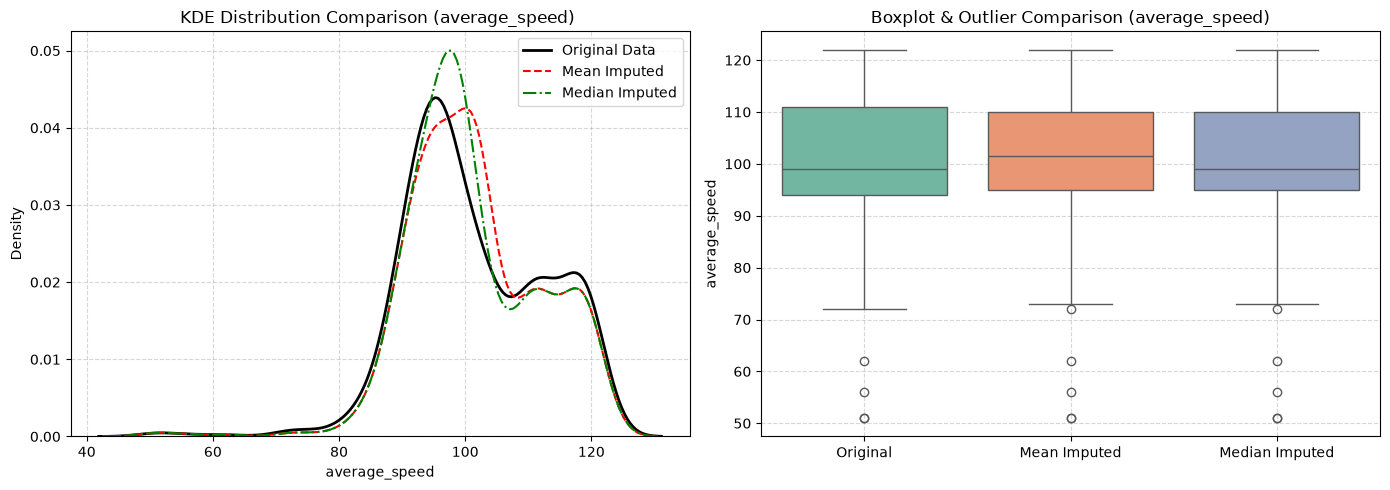

In [68]:
# Compare distributions before and after imputation
plot_imputation_comparison(
    df_orig=df_kt,
    df_mean=df_mean_imp,
    df_median=df_median_imp,
    column="average_speed",
)

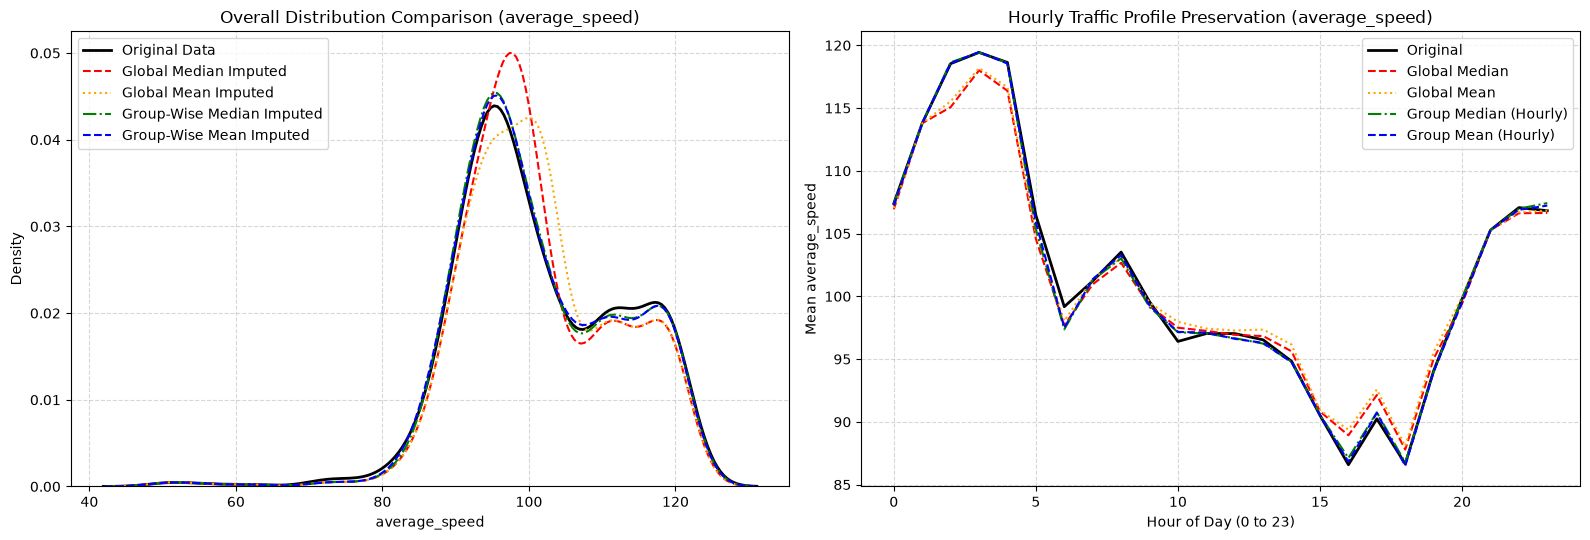

In [69]:
df_median_group_imp = impute_missing_groupwise(
    df=df_missing, target_col="average_speed", group_col="hour", strategy="median"
)

df_mean_group_imp = impute_missing_groupwise(
    df=df_missing, target_col="average_speed", group_col="hour", strategy="mean"
)

# 5. Plot Comparison
plot_all_imputations_comparison(
    df_orig=df_kt,
    df_global_median=df_median_imp,
    df_global_mean=df_mean_imp,
    df_group_median=df_median_group_imp,
    df_group_mean=df_mean_group_imp,
    target_col="average_speed",
    group_col="hour",
)

In [70]:
from helpers.visualization import plot_histogram_intuition

### 📊 Intuition: Histograms & Bin Sensitivity

A **Histogram** visualizes the underlying distribution of a single continuous numerical variable by grouping data into contiguous, non-overlapping intervals called **bins**. It allows us to analyze three fundamental properties of a dataset: **central tendency**, **spread**, and **shape (modality and skewness)**.

---

#### 1. The Impact of Bin Count Selection ($k$)

Selecting the number of bins is a critical hyperparameter in exploratory data analysis. The visual perception of the data's shape changes dramatically based on bin size:

* **Underfitting (Too Few Bins, e.g., $k = 5$):**
  * *Effect:* Oversmooths the data distribution.
  * *Risk:* Obscures local features, such as secondary peaks or subtle traffic congestion clusters, giving a false impression of a simple uniform or unimodal distribution.

* **Overfitting (Too Many Bins, e.g., $k = 50$):**
  * *Effect:* Introduces high variance and fragmentation.
  * *Risk:* Spikes and empty gaps appear due to minor sampling noise rather than true underlying physical trends, making it hard to identify overall pattern limits.

* **Balanced Resolution (Optimal Bins, e.g., $k = 20$):**
  * *Effect:* Strikes a balance between bias and variance.
  * *Rule of Thumb:* Common heuristic methods include **Sturges' Rule** ($k = \lceil \log_2(n) + 1 \rceil$) or the **Freedman-Diaconis Rule** ($\text{Bin Width} = 2 \cdot \frac{IQR}{\sqrt[3]{n}}$).

---

#### 2. Skewness and Central Tendency Divergence

Comparing the position of the **Mean** ($\mu$, red dashed line) and the **Median** ($Q_2$, green dash-dot line) on a histogram provides immediate intuition about data skewness:

1. **Left-Skewed / Negatively Skewed ($\text{Mean} < \text{Median}$):**
   * *Traffic Context:* Typical for highway speeds during peak hours. The baseline speed remains high (~85–90 km/h) for most off-peak hours, but heavy congestion drops speeds to 55–60 km/h, dragging the mean to the left while the median remains stable near the higher baseline.

2. **Symmetric / Normal ($\text{Mean} \approx \text{Median}$):**
   * *Traffic Context:* Found during steady, uncongested midnight hours where vehicle speeds fluctuate naturally around a fixed speed limit.

3. **Right-Skewed / Positively Skewed ($\text{Mean} > \text{Median}$):**
   * *Traffic Context:* Typical for traffic violation counts (e.g., speeding or tailgating events). Most hours have very low violation counts (0 to 10), but occasional enforcement sprees or accidents create long right-hand tails with 100+ violations.

---

#### 3. Modality (Identifying Traffic Patterns)

* **Unimodal:** A single prominent peak (e.g., continuous free-flow speed data).
* **Bimodal / Multimodal:** Multiple distinct peaks. In urban traffic datasets, bimodal histograms in vehicle volume directly highlight the **twin peak phenomenon**: morning rush-hour traffic (08:00 AM) and evening rush-hour traffic (17:00 PM).

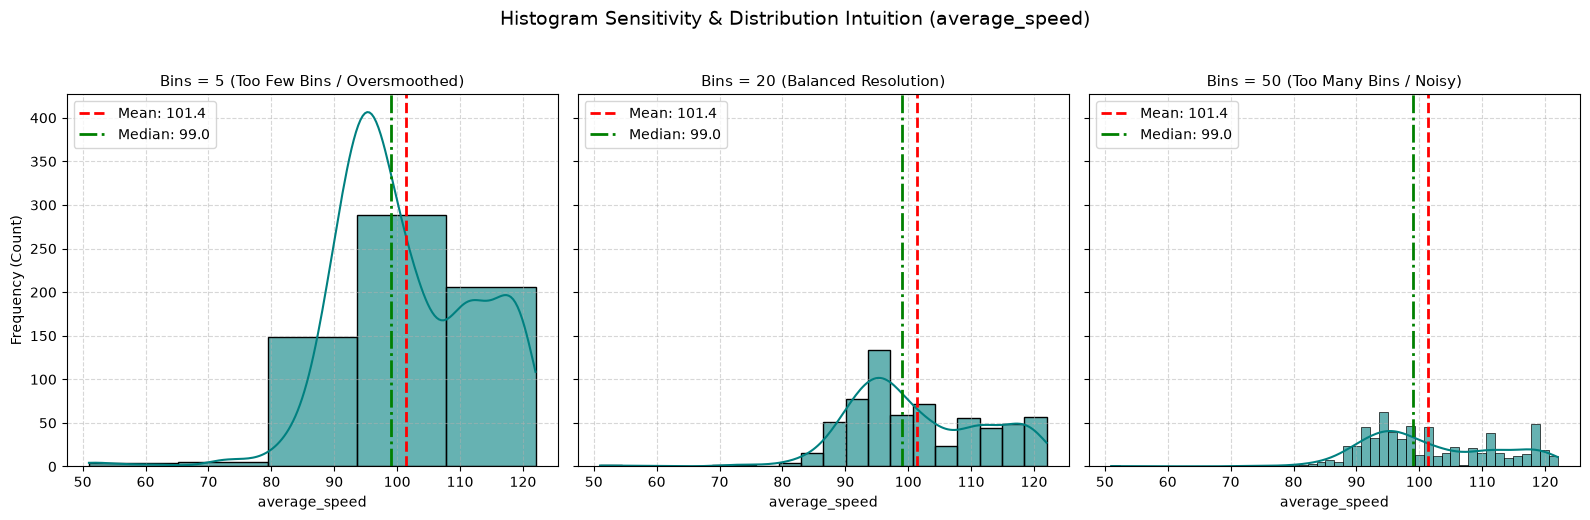

In [71]:
plot_histogram_intuition(
    df=df_kt, column="average_speed", bins_list=[5, 20, 50], show_kde=True
)

### 📦 Intuition: Boxplots & Outlier Handling Strategies

A **Boxplot (Box-and-Whisker Plot)** provides a compact, non-parametric summary of a continuous numerical variable based on its **five-number summary**: Minimum, First Quartile ($Q_1$), Median ($Q_2$), Third Quartile ($Q_3$), and Maximum.

Unlike histograms, boxplots explicitly isolate **statistical outliers**, making them ideal for inspecting traffic volume spikes, sensor anomalies, and speed drops across different hours or road directions.

---

#### 1. Anatomy of a Boxplot & IQR Rule

```text
       Outlier                                                        Outlier
          o      |-----------[   Box   |   Box   ]-------|                   o
            Min Whisker      Q1      Median     Q3     Max Whisker
                             <------- IQR ------->
                         

In [72]:
from helpers.visualization import (
    apply_outlier_treatment,
    detect_iqr_outliers,
    plot_hourly_boxplot,
)

### 📦 Intuition: Interpreting Boxplots & Managing Outliers

A boxplot decomposes numerical data into a **five-number summary**: Minimum, $Q_1$ (25th percentile), Median ($Q_2$), $Q_3$ (75th percentile), and Maximum.

#### 1. Outlier Identification ($1.5 \times IQR$ Rule)
* **Interquartile Range ($IQR$):** $IQR = Q_3 - Q_1$ (Height of the box containing the middle 50% of the data).
* **Upper Whisker Bound:** $Q_3 + 1.5 \times IQR$
* **Lower Whisker Bound:** $Q_1 - 1.5 \times IQR$
* **Outliers:** Individual points plotted beyond the whiskers.

---

#### 2. What to Do with Outliers? (Decision Framework)

1. **Category A: Measurement / Systemic Errors**
   * *Examples:* Negative vehicle counts, volume $= 0$ at 5:00 PM rush hour, average speed recorded as $999\text{ km/h}$.
   * *Root Cause:* Hardware camera failure, power outage, or optical corruption.
   * *Action:* **Convert to `NaN` and impute** using the **Group-Wise (Hourly) Median** helper.

2. **Category B: Genuine Extreme Events**
   * *Examples:* Sudden traffic drop during Nowruz holiday eves or a spike due to major multi-lane highway congestion.
   * *Root Cause:* Real-world behavioral changes or physical bottleneck events.
   * *Action:* **Keep & Annotate** or apply **Winsorization (Capping)** to protect scale-sensitive models (like Linear Regression or K-Means).

---

d:\Uni\Statistics\Statistics Workshop\helpers\visualization.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


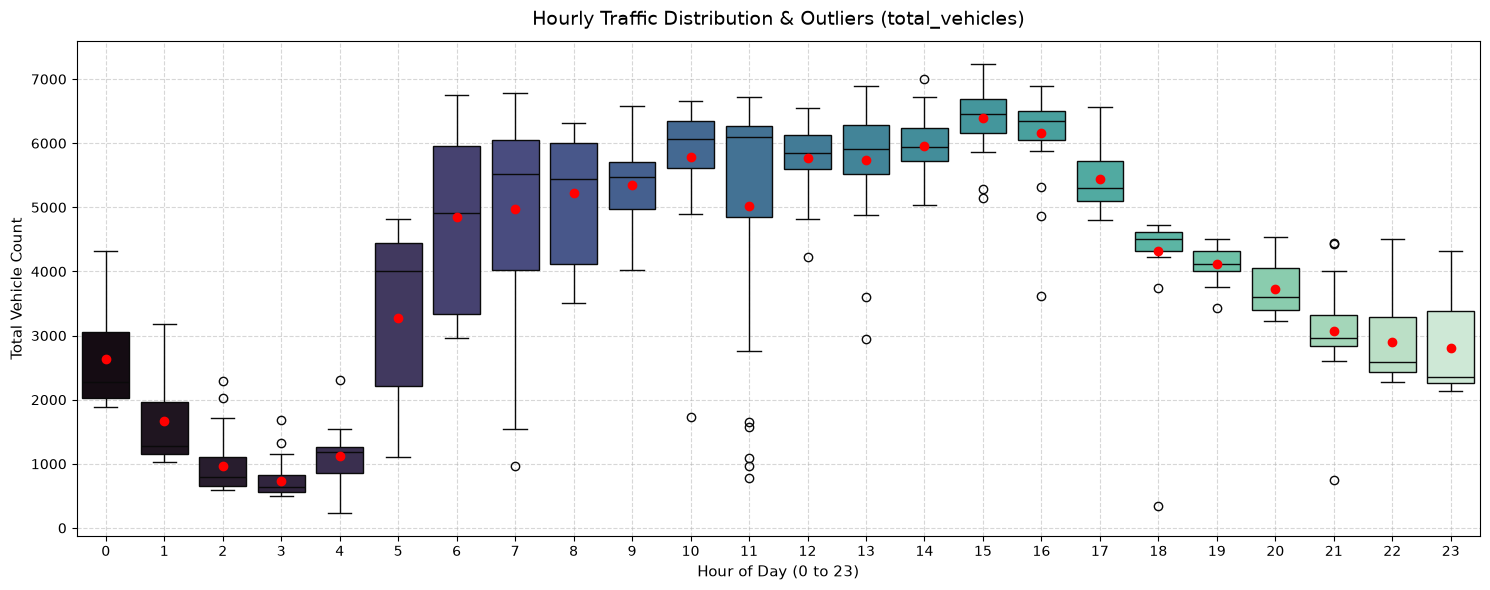

📊 Global IQR Outliers:     0 rows detected (out of 652)
⏰ Group-wise IQR Outliers: 27 rows detected (grouped by hour)

--- 🌐 Global IQR Outlier Records ---
No global outliers detected.

--- ⏰ Group-wise (Hourly) IQR Outlier Records ---


d:\Uni\Statistics\Statistics Workshop\helpers\visualization.py:172: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  return df[outlier_mask].copy()


,start_time,hour,total_vehicles,average_speed
164,1401/07/08 02:00:00,2,2030,114
321,1401/07/16 02:00:00,2,2292,112
322,1401/07/16 03:00:00,3,1682,119
165,1401/07/08 03:00:00,3,1332,116
323,1401/07/16 04:00:00,4,2311,115
347,1401/07/17 07:00:00,7,968,98
348,1401/07/17 10:00:00,10,1734,92
217,1401/07/11 11:00:00,11,781,99
639,1401/07/30 11:00:00,11,1648,98
368,1401/07/18 11:00:00,11,1569,98


In [73]:
# 2. Visual Distribution Across 24 Hours
plot_hourly_boxplot(df_kt, group_col="hour", target_col="total_vehicles")

# 3. Detect Outliers in Traffic Volume
global_outliers = detect_iqr_outliers(
    df_kt, column="total_vehicles", factor=1.5, group_by=None
)

# 2. Group-wise IQR Detection (by Hour)
hourly_outliers = detect_iqr_outliers(
    df_kt, column="total_vehicles", factor=1.5, group_by="hour"
)

# 2. Print Summary Statistics
print(
    f"📊 Global IQR Outliers:     {len(global_outliers)} rows detected (out of {len(df_kt)})"
)
print(
    f"⏰ Group-wise IQR Outliers: {len(hourly_outliers)} rows detected (grouped by hour)\n"
)

# 3. Output Global Outlier Records
print("--- 🌐 Global IQR Outlier Records ---")
if not global_outliers.empty:
    display(
        global_outliers[
            ["start_time", "hour", "total_vehicles", "average_speed"]
        ]
    )
else:
    print("No global outliers detected.")

print("\n--- ⏰ Group-wise (Hourly) IQR Outlier Records ---")
if not hourly_outliers.empty:
    display(
        hourly_outliers[
            ["start_time", "hour", "total_vehicles", "average_speed"]
        ].sort_values(by="hour")
    )
else:
    print("No group-wise outliers detected.")

#### 3. Summary of Code Techniques

* **Capping / Winsorization (`strategy='cap'`):** Clips extreme values to upper and lower IQR bounds. Preserves sample size $N$ and prevents extreme leverage.
* **Log Transformation (`strategy='log'`):** Re-scales heavy right-tailed variables using $\log(1 + x)$.
* **Mask & Impute (`strategy='nan'`):** Sets impossible values to `NaN` so your conditional median imputation function can fill them seamlessly.

d:\Uni\Statistics\Statistics Workshop\helpers\visualization.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


--- 🌐 Boxplot After GLOBAL Capping Strategy ---


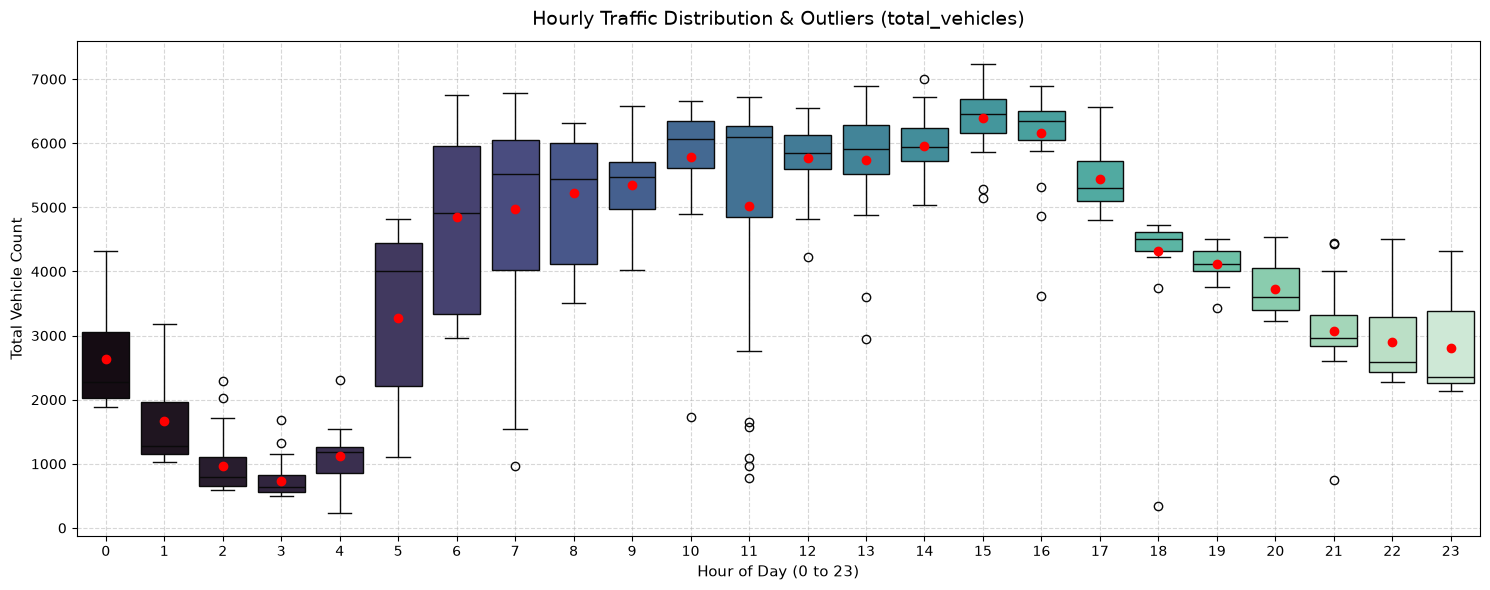

--- ⏰ Boxplot After GROUP-WISE (Hourly) Capping Strategy ---


d:\Uni\Statistics\Statistics Workshop\helpers\visualization.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


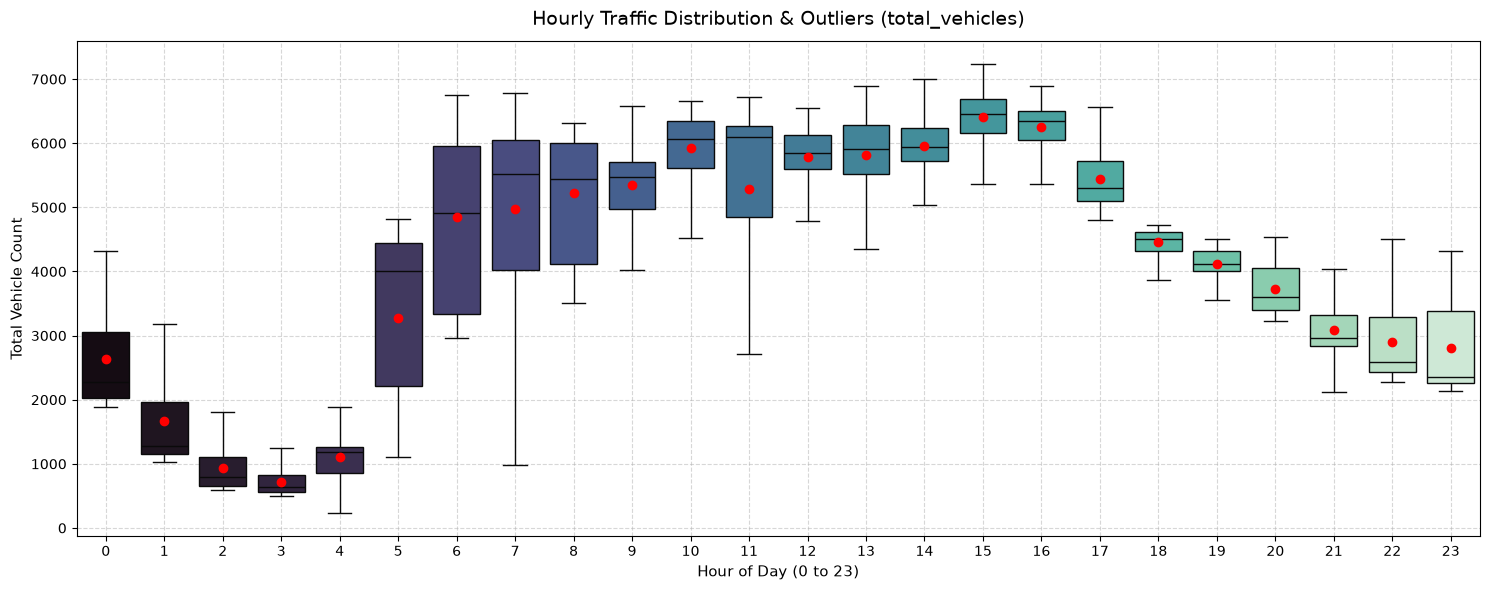

In [74]:
# --- Option A: Global Capping ---
df_kt_global = df_kt.copy()
df_kt_global["total_vehicles"] = apply_outlier_treatment(
    df=df_kt, column="total_vehicles", strategy="cap", group_by=None
)

print("--- 🌐 Boxplot After GLOBAL Capping Strategy ---")
plot_hourly_boxplot(
    df=df_kt_global, group_col="hour", target_col="total_vehicles"
)

# --- Option B: Group-wise (Hourly) Capping ---
df_kt_hourly = df_kt.copy()
df_kt_hourly["total_vehicles"] = apply_outlier_treatment(
    df=df_kt, column="total_vehicles", strategy="cap", group_by="hour"
)

print("--- ⏰ Boxplot After GROUP-WISE (Hourly) Capping Strategy ---")
plot_hourly_boxplot(
    df=df_kt_hourly, group_col="hour", target_col="total_vehicles"
)

In [75]:
from helpers.visualization import plot_scatter_intuition

### 📈 Intuition: Scatter Plots & Traffic Breakdown Dynamics

A **Scatter Plot** maps two continuous numerical variables on Cartesian coordinates $(X, Y)$ to reveal correlation, clustering, functional dependencies, and non-linear physical regimes.

---

1. **Direction & Strength of Association:**
   * **Positive Relationship:** As $X$ increases, $Y$ increases (e.g., higher vehicle counts usually correlate with higher total speed violations).
   * **Negative Relationship:** As $X$ increases, $Y$ decreases (e.g., higher traffic volume causes lower average speed).

2. **Linear vs. Non-Linear Realities (Traffic Breakdown):**
   * *Linear Fit Trap (Red Line):* Assuming a constant linear relationship between vehicle volume and speed oversimplifies real-world physics.
   * *LOWESS Fit Curve (Green Dashed Line):* Captures the **non-linear regime shift**.
     * **Free-Flow Zone ($0 \text{ to } 4,500 \text{ veh/h}$):** Vehicles move independently. Average speed remains steady near free-flow speed (~85–90 km/h) despite volume growth.
     * **Congestion/Breakdown Zone ($> 5,000 \text{ veh/h}$):** Highway capacity limit is reached. Headways compress, creating a steep non-linear drop in average speed down to 50–55 km/h.

3. **Multivariate Analysis via Aesthetics (`hue` / `size` / `style`):**
   * By assigning a 3rd feature like `hour` or `is_weekend` to the dot color (`hue`), students can distinguish whether low speeds occur during morning vs. evening rush hours.

---


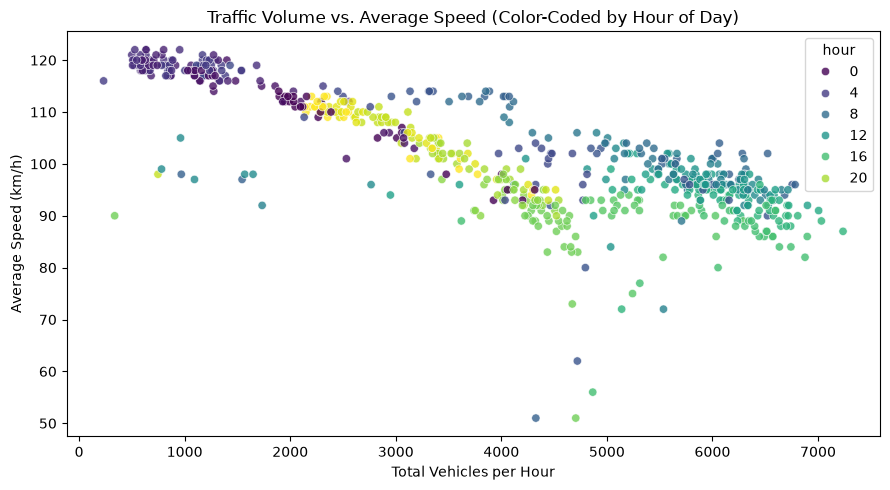

In [76]:
plot_scatter_intuition(
    df=df_kt,
    x_col="total_vehicles",
    y_col="average_speed",
    hue_col="hour",
)

### 📈 Intuition: Average Hourly Traffic Profile & Peak Hour Definition

Analyzing the **24-hour traffic volume curve** as a continuous line plot reveals how vehicle density ramps up and ramps down throughout the day. This provides a data-driven basis for defining peak congestion periods rather than relying on arbitrary assumptions.

---

#### 1. Why Use a Line Plot for Hourly Profiles?

* **Temporal Continuity:** Traffic flow evolves continuously across consecutive hours. A line plot highlights the **rate of change** (slopes)—showing exactly how fast morning congestion builds up compared to evening dispersal.
* **Pattern Recognition:** It clearly illustrates cyclical human behavior, highlighting the **twin peak phenomenon** typical of commuter corridors:
  * **Morning Peak (Inbound Commute):** Rapid rise in volume as vehicles travel toward employment hubs (e.g., Karaj $\rightarrow$ Tehran between 06:00 and 08:00 AM).
  * **Evening Peak (Outbound Commute):** Secondary rush hour during return trips (e.g., 16:00 to 18:00 PM).
  * **Night Trough:** Minimal vehicle counts between 01:00 AM and 04:00 AM representing free-flow conditions.

---

#### 2. Data-Driven Peak Classification (Quantile Cutoff)

Instead of hardcoding peak hours, we apply an upper-quantile threshold to classify hours systematically:

1. **Quantile Threshold ($\ge 75^{\text{th}}$ Percentile):**
   * Hours where average traffic volume falls into the **top 25%** of the 24-hour profile are flagged as **Peak Hours** ($\text{is\_peak} = 1$).
   * All remaining hours are classified as **Off-Peak Hours** ($\text{is\_peak} = 0$).

2. **Downstream Feature Engineering:**
   * **Conditional Imputation:** Grouping missing value imputations by `[hour, is_peak]` prevents off-peak baseline speeds from skewing rush-hour estimates.
   * **Outlier Contextualization:** An unexpectedly low volume during a designated Peak Hour immediately flags potential sensor failure or major highway blockages.

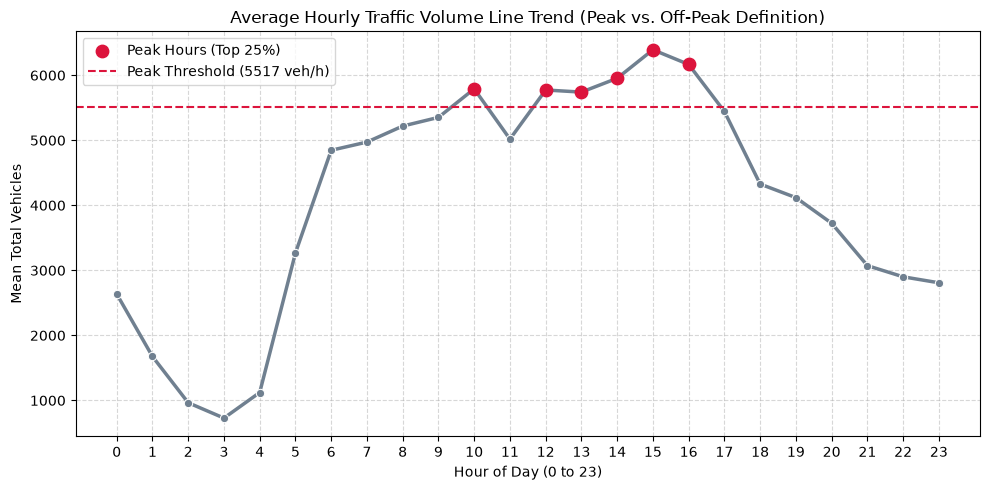

🔴 Peak Hours: [10, 12, 13, 14, 15, 16]
🔵 Off-Peak Hours: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 17, 18, 19, 20, 21, 22, 23]


In [78]:
peak_hours, off_peak_hours = plot_hourly_traffic_profile(
    df=df_kt,
    hour_col="hour",
    volume_col="total_vehicles",
    peak_threshold_quantile=0.75,
)

print(f"🔴 Peak Hours: {peak_hours}")
print(f"🔵 Off-Peak Hours: {off_peak_hours}")